# Pizza Sales Exploratory Data Analysis & Visualization
This notebook analyzes the `pizza_sales_transformed_data.xlsx` file, mirroring the insights generated across our Excel, Power BI, and Tableau dashboards. We will extract high-level KPIs, analyze order trends, and visualize top/bottom performers using Matplotlib.

---

## Imports & Data Loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.style.use('seaborn-v0_8-whitegrid')  # Set style

file_path = '../02_Transformed_data/pizza_sales_transformed_data.xlsx'
df = pd.read_excel(file_path)
df['order_date'] = pd.to_datetime(df['order_date'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   pizza_id        48620 non-null  int64         
 1   order_id        48620 non-null  int64         
 2   unique_order    48620 non-null  int64         
 3   pizza_name_id   48620 non-null  object        
 4   quantity        48620 non-null  int64         
 5   order_date      48620 non-null  datetime64[ns]
 6   order_time      48620 non-null  object        
 7   unit_price      48620 non-null  float64       
 8   total_price     48620 non-null  float64       
 9   pizza_size      48620 non-null  object        
 10  pizza_category  48620 non-null  object        
 11  pizza_name      48620 non-null  object        
 12  order_weeknum   48620 non-null  int64         
 13  order_day       48620 non-null  object        
 14  order_month     48620 non-null  object        
 15  or

#### Key Insights:
The dataset successfully loads 48,620 transaction records across 16 structured columns with clean datetime, numeric, and categorical formats, requiring no major imputation.

#### Recommendations:
Establish automated schema validation checks in your ETL pipeline to maintain data integrity as new monthly order files arrive.

---

## 1. High-Level KPI Summary
Calculating core business metrics: Total Revenue, Total Orders, Total Pizzas Sold, Average Order Value (AOV), and Average Pizzas per Order.

In [2]:
total_revenue = df['total_price'].sum()
total_orders = df['unique_order'].sum()
total_pizzas_sold = df['quantity'].sum()
aov = total_revenue / total_orders
avg_pizzas_per_order = total_pizzas_sold / total_orders

print("--- PIZZA SALES YEARLY KPI REPORT ---")
print(f"Total Revenue        : ${total_revenue:,.2f}")
print(f"Total Orders         : {total_orders:,}")
print(f"Total Pizzas Sold    : {total_pizzas_sold:,}")
print(f"Average Order Value  : ${aov:.2f}")
print(f"Avg Pizzas / Order   : {avg_pizzas_per_order:.2f}")

print("\n--- PIZZA SALES MONTHLY AVERAGE KPI REPORT ---")
print(f"Average Revenue      : ${total_revenue/12:,.2f}")
print(f"Average Orders       : {total_orders/12:,.0f}")
print(f"Average Pizzas Sold  : {total_pizzas_sold/12:,.0f}")

--- PIZZA SALES YEARLY KPI REPORT ---
Total Revenue        : $817,860.05
Total Orders         : 21,350
Total Pizzas Sold    : 49,574
Average Order Value  : $38.31
Avg Pizzas / Order   : 2.32

--- PIZZA SALES MONTHLY AVERAGE KPI REPORT ---
Average Revenue      : $68,155.00
Average Orders       : 1,779
Average Pizzas Sold  : 4,131


#### Key Insights:
The business generated `$817,860.05` in total revenue across 21,350 orders (49,574 pizzas sold), averaging an Average Order Value (AOV) of `$38.31` and 2.32 pizzas per order. Monthly averages sit consistently near `$68,155` in revenue.

#### Recommendations:
Introduce bundled meal deals (e.g., family combos or side-and-drink packages) to push the average items per order above 2.5 and boost the AOV past $40.

---

## 2. Order Trends (Hourly & Daily)
Visualizing peak operational windows to help align kitchen staffing and delivery schedules.

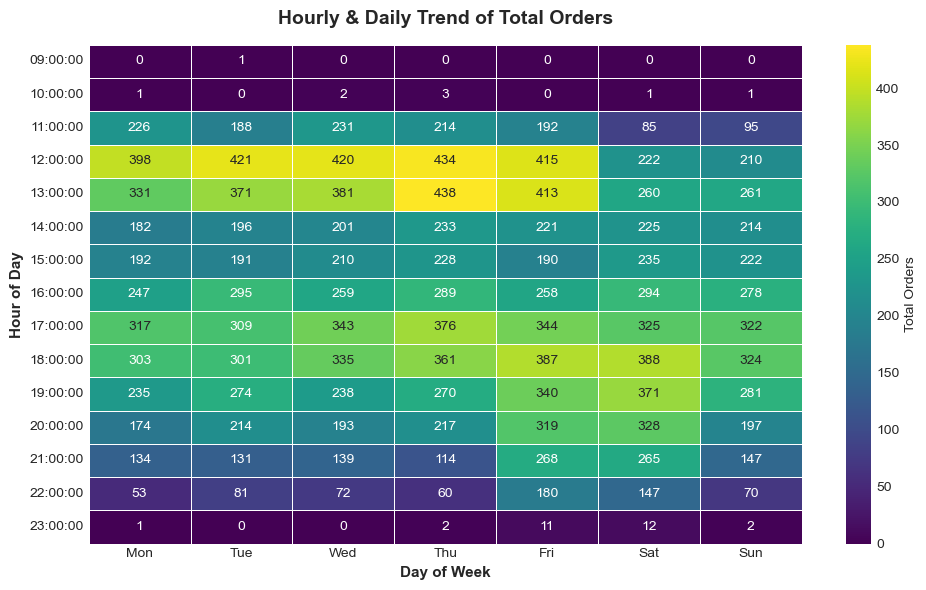

In [3]:
day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
heatmap_data = df.pivot_table(
    index='order_hour', 
    columns='order_day', 
    values='unique_order', 
    aggfunc='sum'
).reindex(columns=day_order).sort_index(ascending=True).fillna(0)

# 3. Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_data, 
    cmap='viridis', 
    annot=True, 
    fmt='g',    # General format
    linewidths=0.5,
    cbar_kws={'label': 'Total Orders'}
)

# 4. Set titles and labels
plt.title('Hourly & Daily Trend of Total Orders', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Day of Week', fontsize=11, fontweight='bold')
plt.ylabel('Hour of Day', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

#### Key Insights:
Order volume peaks heavily during standard lunch (12:00 PM – 2:00 PM, hitting over 400 orders per hour) and dinner windows (5:00 PM – 9:00 PM), with Thursday and Friday evenings showing the highest operational density.   

#### Recommendations:
Optimize kitchen staffing and prep schedules around peak lunch and Friday dinner rushes to reduce ticket times and prevent delivery bottlenecks.

---

## 3. Monthly Trend of Total Orders & Revenue
Analyzing month-over-month performance using a bar + line combination chart to observe how order volume correlates with total revenue throughout the year.

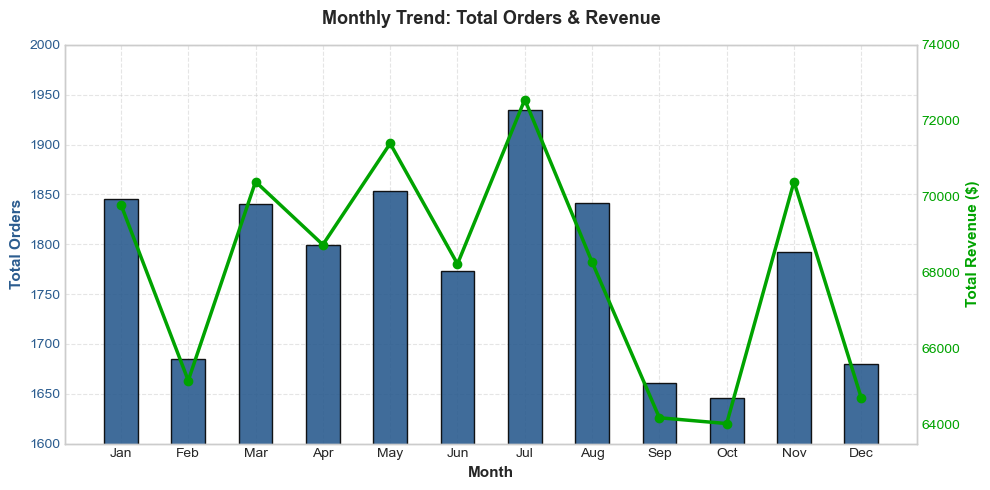

In [4]:
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

monthly_df = df.groupby(df['order_month']).agg(
    total_orders=('unique_order', 'sum'),
    total_revenue=('total_price', 'sum')
).reindex(month_order).reset_index()

# Set up figure and primary axis (Total Orders)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = '#2b5c8f'
ax1.set_xlabel('Month', fontsize=11, fontweight='bold')
ax1.set_ylabel('Total Orders', color=color, fontsize=11, fontweight='bold')
bars = ax1.bar(monthly_df['order_month'], monthly_df['total_orders'], color=color, alpha=0.9, width=0.5, label='Total Orders', edgecolor='black')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylim(1600, 2000)

# Create secondary axis sharing the same x-axis (Total Revenue)
ax2 = ax1.twinx()  
color = '#00A300'
ax2.set_ylabel('Total Revenue ($)', color=color, fontsize=11, fontweight='bold')
line = ax2.plot(monthly_df['order_month'], monthly_df['total_revenue'], color=color, marker='o', linewidth=2.5, linestyle='-', label='Total Revenue')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False) # Avoid overlapping gridlines
ax2.set_ylim(63500, 74000)

# Title and Layout
plt.title('Monthly Trend: Total Orders & Revenue', fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

#### Key Insights:
Revenue and order volumes remain remarkably stable month-over-month throughout the year, hovering around `$64,000` to `$72,500` monthly, with slight peaks in May (`$71,403`) and July (`$72,558`). Notably, November achieves a higher average order value (`$39.28` per order) despite moderate overall order volume.

#### Recommendations:
Since baseline demand is steady, launch targeted seasonal promotions or limited-time specialty pizzas during slower months (like October and February) to drive incremental growth. Additionally, analyze and replicate November's basket size or upsell strategy across other months to boost order values year-round.

---

## 4. Percentage of Sales by Pizza Category
Highlighting product category performance share.

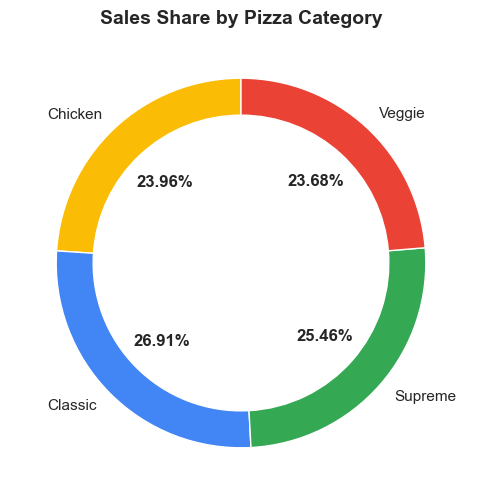

In [5]:
category_sales = df.groupby('pizza_category')['total_price'].sum()

fig, ax = plt.subplots(figsize=(6, 6))
wedges, texts, autotexts = ax.pie(
    category_sales, 
    labels=category_sales.index, 
    autopct='%1.2f%%', 
    startangle=90,
    colors=['#FBBC05','#4285F4','#34A853','#EA4335'],
    wedgeprops=dict(width=0.2, edgecolor='w') # Creates a Donut Chart effect
)

plt.setp(autotexts, size=12, weight="bold")
plt.setp(texts, size=11)
ax.set_title('Sales Share by Pizza Category', fontsize=14, fontweight='bold')
plt.show()

### 4.1. Pizza Size Availability by Category
To understand why certain sizes (like X-Large and XX-Large) appear less frequently in total sales, let's inspect which sizes are offered across each product category.

In [6]:
category_size_matrix = pd.crosstab(df['pizza_category'], df['pizza_size']).astype(bool)
print(category_size_matrix)

pizza_size      Large  Medium  Small  X-Large  XX-Large
pizza_category                                         
Chicken          True    True   True    False     False
Classic          True    True   True     True      True
Supreme          True    True   True    False     False
Veggie           True    True   True    False     False


#### Key Insights:
Revenue is evenly distributed across all four categories: Classic (26.9%), Supreme (25.5%), Chicken (24.0%), and Veggie (23.7%). No single category dominates or lags significantly.

#### Recommendations:
Maintain balanced inventory levels across all four categories since customer preference is diverse, but test cross-category offers (e.g., buy a Large Classic pizza, get a Small Veggie pizza 50% off) to encourage menu exploration.

---

## 5. Percentage of Sales by Pizza Size

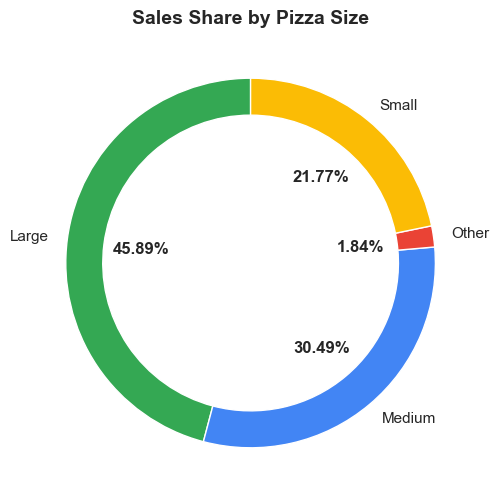

In [7]:
# size_sales = df.groupby('pizza_size')['total_price'].sum()

df['size_grouped'] = df['pizza_size'].replace({'X-Large': 'Other', 'XX-Large': 'Other'})
size_sales = df.groupby('size_grouped')['total_price'].sum()

fig, ax = plt.subplots(figsize=(6, 6))
wedges, texts, autotexts = ax.pie(
    size_sales, 
    labels=size_sales.index, 
    autopct='%1.2f%%', 
    startangle=90,
    colors=['#34A853','#4285F4','#EA4335','#FBBC05'],
    wedgeprops=dict(width=0.2, edgecolor='w') # Creates a Donut Chart effect
)

plt.setp(autotexts, size=12, weight="bold")
plt.setp(texts, size=11)
ax.set_title('Sales Share by Pizza Size', fontsize=14, fontweight='bold')
plt.show()

### 4.1 Average Price Analysis by Category & Size
This pivot table breaks down the average unit price for each pizza category across different size options, highlighting pricing distribution across the menu.

In [8]:
avg_price_pivot = df.pivot_table(
    index='pizza_category',
    columns='pizza_size',
    values='unit_price',
    aggfunc='mean'
).round(2)

print("Average Pizza Price by Category and Size ($):")
display(avg_price_pivot)

Average Pizza Price by Category and Size ($):


pizza_size,Large,Medium,Small,X-Large,XX-Large
pizza_category,,,,,
Chicken,20.75,16.75,12.75,NaN,NaN
Classic,18.38,14.74,11.38,25.5,35.95
Supreme,20.65,16.43,14.05,NaN,NaN
Veggie,19.30,15.94,12.16,NaN,NaN


#### Key Insights:
Large pizzas drive nearly half of all revenue (45.9%), followed by Medium (30.5%) and Small (21.8%), while X-Large/XX-Large sizes contribute a negligible 1.8%.   

#### Recommendations:
Promote large-size upsells at checkout points (online and in-store). If discontinuing X-Large and XX-Large sizes is not preferred, run introductory advertisements and bundle offers (e.g., promotional discounts on larger sizes) to build customer awareness and drive trial volumes. Once steady demand is established, gradually scale back the discounts or adjust pricing to offset initial marketing expenses and protect profit margins.

---

## 5. Top 5 Best-Selling Pizzas by Revenue
Identifying hero products that drive the highest total revenue.

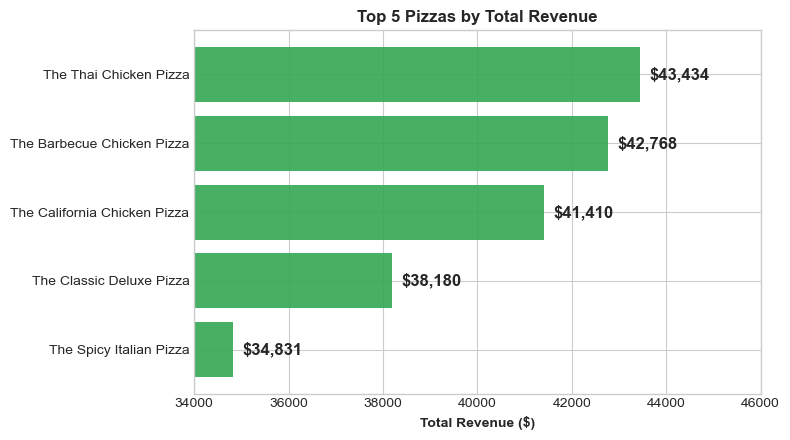

In [9]:
top_pizzas = df.groupby('pizza_name')['total_price'].sum().nlargest(5).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(top_pizzas.index, top_pizzas.values, color='#34A853', alpha=0.9)
ax.set_title('Top 5 Pizzas by Total Revenue', fontsize=12, fontweight='bold')
ax.set_xlabel('Total Revenue ($)', fontsize=10, fontweight='bold')
ax.set_xlim(34000, 46000)

# Add data labels on bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 200, bar.get_y() + bar.get_height()/2, f'${width:,.0f}', 
            va='center', ha='left', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

#### Key Insights:
Chicken-based pizzas dominate top revenue earnings, led by The Thai Chicken Pizza (`$43,434`), The Barbecue Chicken Pizza (`$42,768`), and The California Chicken Pizza (`$41,410`).   

#### Recommendations:
Feature top revenue-generating chicken pizzas prominently on digital menu banners and loyalty app landing pages to capitalize on their high profit margins.

---

## 6. Bottom 5 Pizzas by Total Revenue
Identifying underperforming menu items to support menu rationalization and inventory optimization.

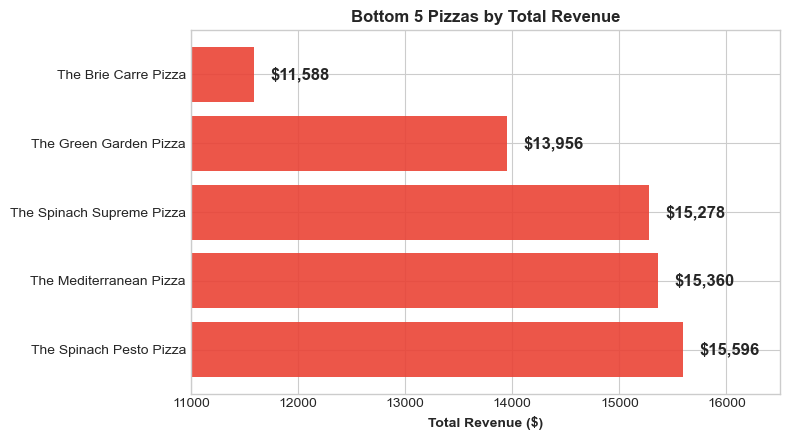

In [10]:
bottom_pizzas = df.groupby('pizza_name')['total_price'].sum().nsmallest(5).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(bottom_pizzas.index, bottom_pizzas.values, color='#EA4335', alpha=0.9)
ax.set_title('Bottom 5 Pizzas by Total Revenue', fontsize=12, fontweight='bold')
ax.set_xlabel('Total Revenue ($)', fontsize=10, fontweight='bold')
ax.set_xlim(11000, 16500)

# Add data labels on bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 150, bar.get_y() + bar.get_height()/2, f'${width:,.0f}', 
            va='center', ha='left', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

#### Key Insights:
The Brie Carre Pizza generates the lowest revenue (`$11,589`), alongside specialty options like The Green Garden Pizza (`$13,956`) and The Spinach Supreme Pizza (`$15,278`).   

#### Recommendations:
Review ingredient costs for low-revenue specialty pizzas. Either revamp their recipes with more popular toppings or rotate them off the permanent menu in favor of seasonal specials.

---

## 7. Top 5 Best-Selling Pizzas by Quantity Sold
Identifying the core volume drivers that move the highest number of physical units.

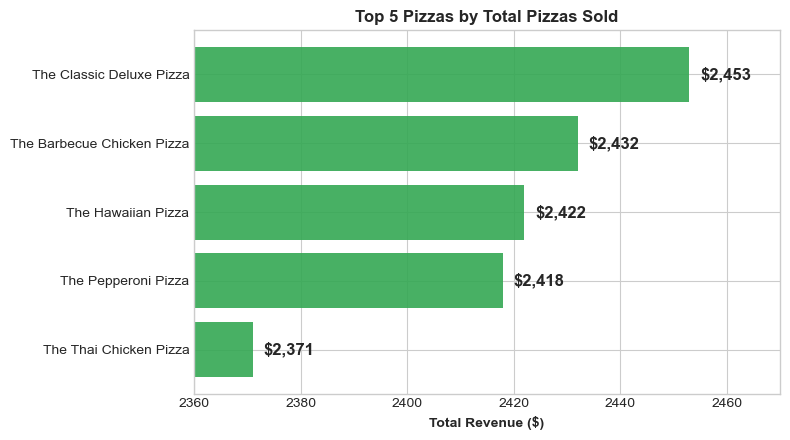

In [11]:
top_pizzas_by_quantity = df.groupby('pizza_name')['quantity'].sum().nlargest(5).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(top_pizzas_by_quantity.index, top_pizzas_by_quantity.values, color='#34A853', alpha=0.9)
ax.set_title('Top 5 Pizzas by Total Pizzas Sold', fontsize=12, fontweight='bold')
ax.set_xlabel('Total Revenue ($)', fontsize=10, fontweight='bold')
ax.set_xlim(2360, 2470)

# Add data labels on bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 2, bar.get_y() + bar.get_height()/2, f'${width:,.0f}', 
            va='center', ha='left', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

#### Key Insights:
Volume leaders differ slightly from revenue leaders: The Classic Deluxe Pizza (2,453 sold), The Barbecue Chicken Pizza (2,432 sold), and The Hawaiian Pizza (2,422 sold) lead in unit turnover.

#### Recommendations:
Ensure high-volume staples like Classic Deluxe and Hawaiian are always prepped with ample dough and ingredient stock to avoid stockouts during peak hours.

---

## 8. Bottom 5 Pizzas by Total Quantity Sold
Highlighting lower-volume menu items that may require menu rationalization or targeted promotion.

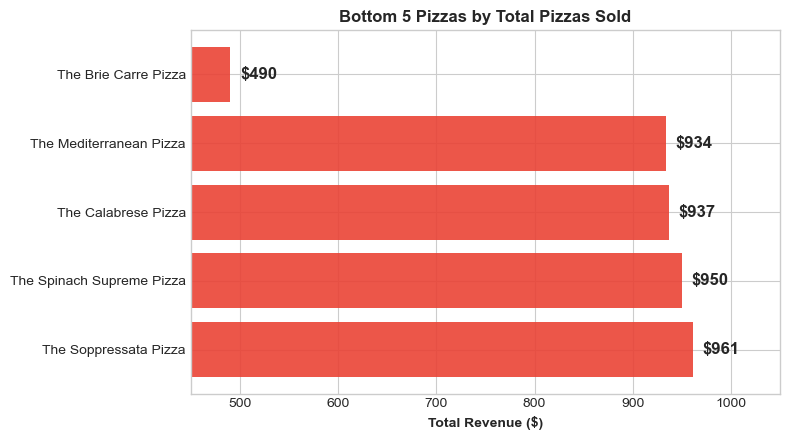

In [12]:
bottom_pizzas_by_quantity = df.groupby('pizza_name')['quantity'].sum().nsmallest(5).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(bottom_pizzas_by_quantity.index, bottom_pizzas_by_quantity.values, color='#EA4335', alpha=0.9)
ax.set_title('Bottom 5 Pizzas by Total Pizzas Sold', fontsize=12, fontweight='bold')
ax.set_xlabel('Total Revenue ($)', fontsize=10, fontweight='bold')
ax.set_xlim(450, 1050)

# Add data labels on bars
for bar in bars:
    width = bar.get_width()
    ax.text(width + 10, bar.get_y() + bar.get_height()/2, f'${width:,.0f}', 
            va='center', ha='left', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

#### Key Insights:
The Brie Carre Pizza is also the lowest in volume (only 490 units sold), joined by niche items like The Mediterranean Pizza (934 sold) and The Calabrese Pizza (937 sold). 

#### Recommendations:
Investigate whether low sales volumes are due to lack of customer awareness or poor taste profile, and test offering them as limited-time trials before keeping them on the menu.

---
# Summary:-

## Bonus Chart: Category-wise Size Distribution & Revenue Contribution

To bridge the gap between macro-level category totals and individual product performance, this faceted heatmap illustrates exactly how much percentage contribution each pizza size makes toward its respective category's total sales.

#### Assumption:
**Size Availability**: It is assumed that zero-sale combinations in a specific size indicate that the particular pizza is not offered in that size.

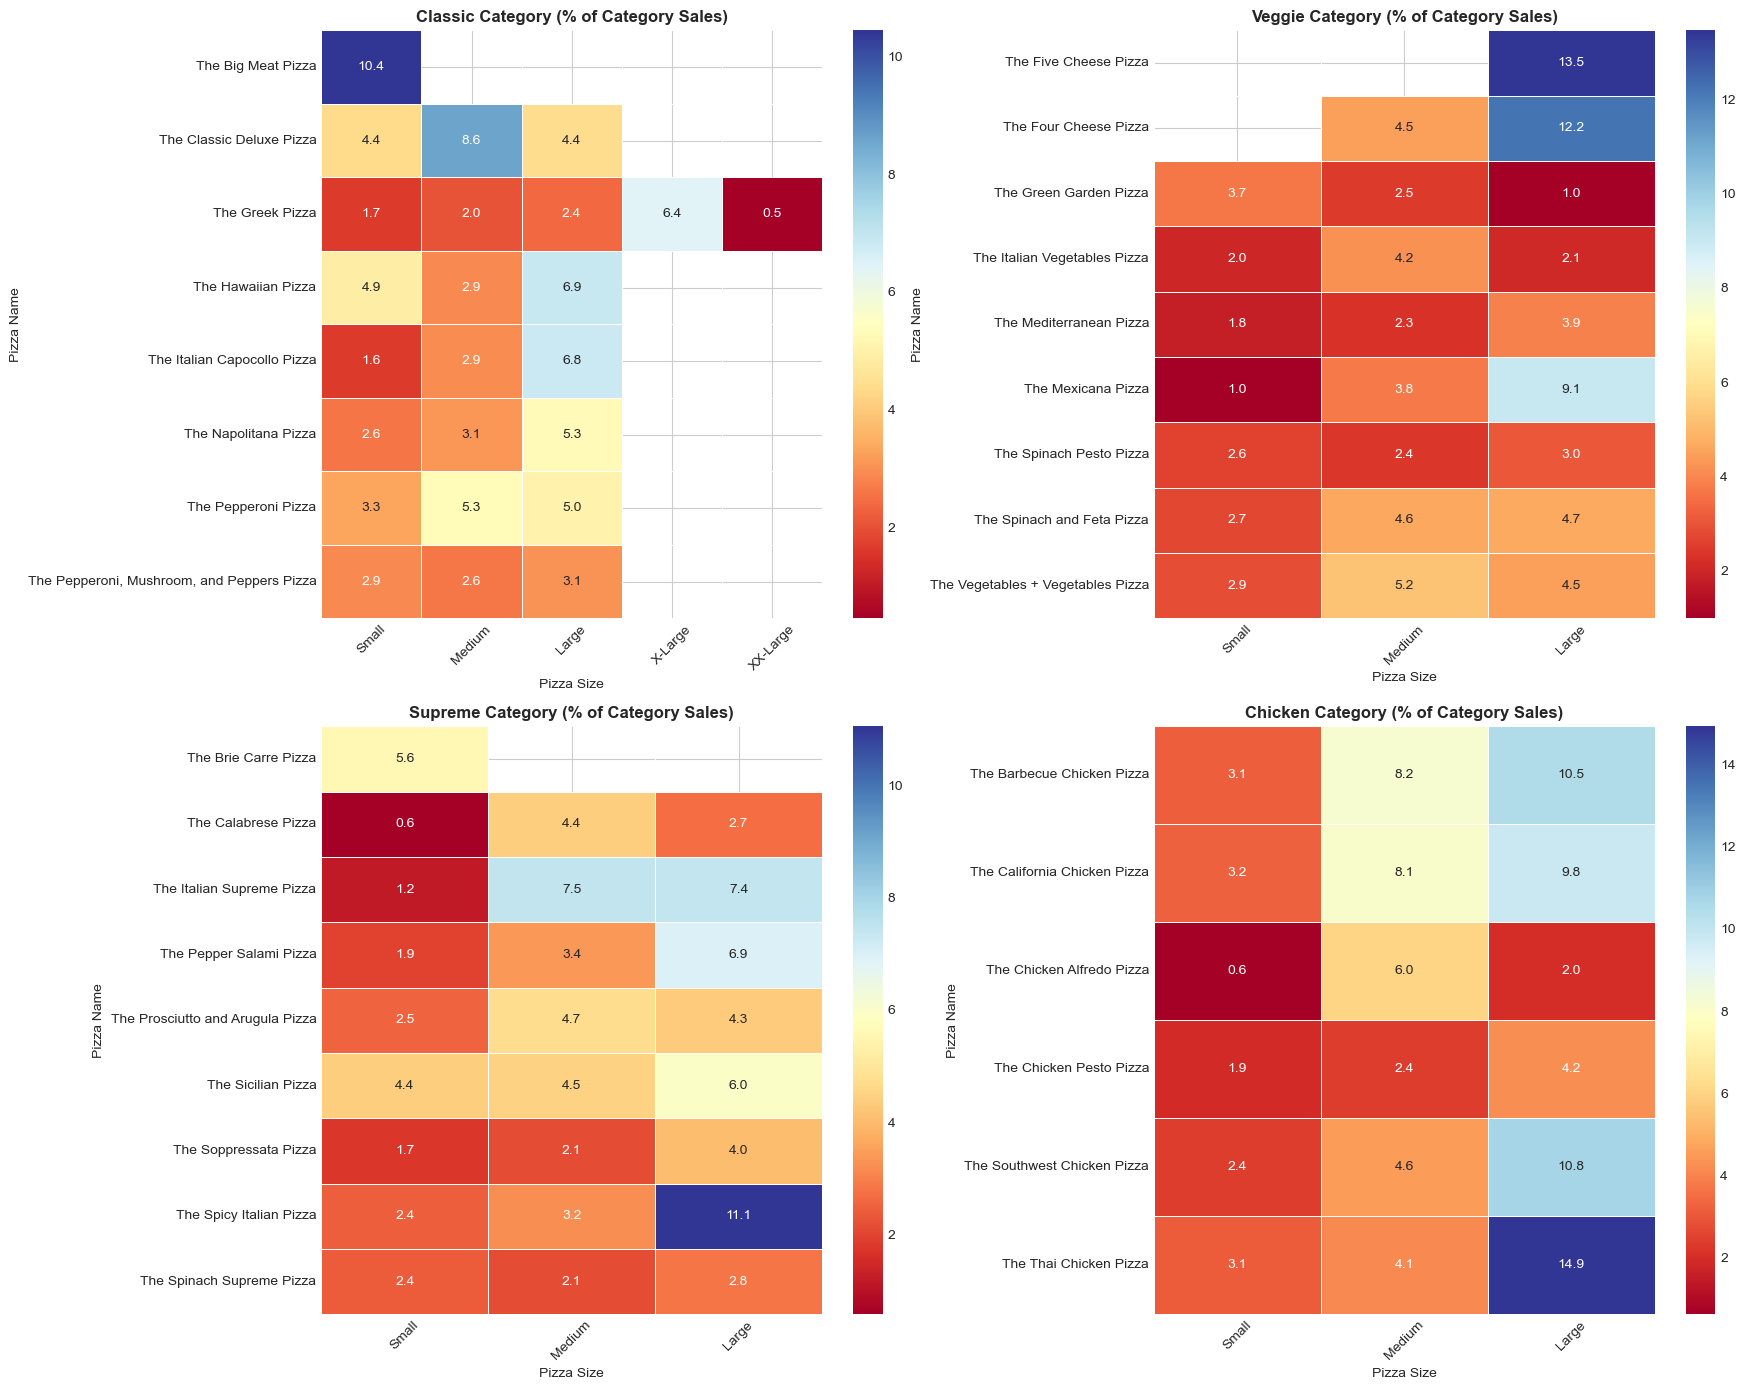

In [13]:
# Calculate category totals
category_totals = df.groupby('pizza_category')['total_price'].sum()

# Calculate percentage contribution per size/pizza without grouping sizes
df_grouped = df.groupby(['pizza_category', 'pizza_name', 'pizza_size'])['total_price'].sum().reset_index()
df_grouped['cat_total'] = df_grouped['pizza_category'].map(category_totals)
df_grouped['pct_of_cat'] = (df_grouped['total_price'] / df_grouped['cat_total']) * 100

# Define a consistent size order for columns if desired
size_order = ['Small', 'Medium', 'Large', 'X-Large', 'XX-Large']

# Create figure with subplots for each category
categories = df['pizza_category'].unique()
fig, axes = plt.subplots(2, 2, figsize=(18, 14), sharex=False)
axes = axes.flatten()

for i, cat in enumerate(categories):
    cat_data = df_grouped[df_grouped['pizza_category'] == cat]
    
    # Pivot table with 0 filled as NaN
    pivot_data = cat_data.pivot_table(index='pizza_name', columns='pizza_size', values='pct_of_cat', fill_value=np.nan)
    
    # Reindex columns to match standard size ordering if present in the category
    existing_sizes = [s for s in size_order if s in pivot_data.columns]
    pivot_data = pivot_data[existing_sizes]
    
    # Plot heatmap (null values show up as blank cells)
    sns.heatmap(pivot_data, annot=True, fmt=".1f", cmap="RdYlBu", cbar=True, ax=axes[i], linewidths=.5, mask=pivot_data.isna())

    axes[i].set_title(f"{cat} Category (% of Category Sales)", fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Pizza Size", fontsize=10)
    axes[i].set_ylabel("Pizza Name", fontsize=10)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Insights:
* **High-Demand Drivers (>10% category share)**:
  * *Classic*: The Big Meat Pizza (Small) — **10.4%**
  * *Veggie*: The Five Cheese Pizza (Large) — **13.5%** & The Four Cheese Pizza (Large) — **12.2%**
  * *Supreme*: The Spicy Italian Pizza (Large) — **11.1%**
  * *Chicken*: The Thai Chicken Pizza (Large) — **14.9%**, Southwest Chicken (Large) — **10.8%**, & Barbecue Chicken (Large) — **10.5%**
* **Low-Demand Items (1-2% category share)**:
  * *Classic*: The Greek Pizza (Small) — **1.7%** & The Italian Capocollo Pizza (Small) — **1.6%**
  * *Veggie*: The Mediterranean Pizza (Small) — **1.8%**, The Green Garden Pizza (Large) — **1.0%**, & The Mexican Pizza (Small) — **1.0%**
  * *Supreme*: The Pepper Salami Pizza (Small) — **1.9%**, The Sopresatta Pizza (Small) — **1.7%**, & The Italian Supreme Pizza (Small) — **1.2%**
  * *Chicken*: The Chicken Paesto Pizza (Small) — **1.9%**
* **Ultra-Low-Demand Long-Tail Items (<1% category share)**: Consists of niche items and smaller sizes that consume inventory space with minimal return.
  * *Classic*: The Greek Pizza XX-Large at **0.5%**
  * *Supreme*: The Calabrese Pizza Small at **0.6%**
  * *Chicken*: The Chicken Alfredo Pizza Small at **0.6%** 
* **The Brie Carre Pizza**: It has an exceptionally high unit price (`$23.65`) despite only being available in a small size, which limits its mass market appeal.

#### Recommendations:
1. **Optimize Product Offerings**: Discontinue ultra-low-selling variants (<1% share) to streamline kitchen prep and reduce waste.
2. **Reallocate Size Inventory**: Remove the underperforming XX-Large size from *The Greek Pizza* (0.5% share) and introduce X-Large/XX-Large sizes for top revenue drivers in each category (*The Thai Chicken Pizza*, *The Five Cheese Pizza*, etc.).
3. **Size Expansion**: Introduce medium and large variants for the highly demanded *The Big Meat Pizza*, which is currently restricted to small sizes.
4. **Strategic Combo Bundling**: Pair high-demand staples (>10% share) with slow-moving items (1-2%) under same-category bundle offers to boost Average Order Value (AOV) and clear inventory.
5. **Discount Coupon**: Upon purchasing moderate-demand items (2-10% share), issue a discount coupon (to help build a regular customer base) offering a discount on the next purchase of low-demand items (1-2% share)—such as a 10% discount in the same category (to improve low-performing pizzas) and a 15% discount in another category (to motivate consumers to cross-explore categories).
6. **Low Price on a Particular Day**: Reduce the price of all low-demand (<2% share) small pizzas to a flat $11 on Sunday (the lowest revenue day), helping attract customers from competitors.
7. **Low Price at Specific Times**: Offer a 5% discount (or complementary items like French fries) on all low-demand (<2% share) small pizzas during off-peak hours (2:00 PM – 4:00 PM and 9:00 PM – 11:00 PM) on Thursday and Friday (high-revenue days) to distribute customer traffic and optimize staff efficiency.

#### Strategy:-
1. **Advertising Cost**: If discounts and offers do not negatively impact profit margins, the company should take immediate action; this increases brand popularity (effectively treating it as an advertising cost).
2. **Price Adjustments**: If running aggressive discounts is unfeasible, increase baseline prices slightly to absorb offer costs. Adjust pricing slightly on a monthly basis according to demand fluctuations.
3. **Discount Capping**: Avoid overloading promotions. Choose them effectively, limiting active offers to no more than 3–4 at a time, and update them on a fixed schedule.

#### Human Tendency & Consumer Behavior:
1. **Discount Attraction**: Consumers are naturally drawn to promotional offers and will willingly buy additional items or larger portions to unlock percentage-based discounts.
2. **Regular Customer Retention**: Holding a company discount coupon motivates customers to choose your brand over competitors to redeem their savings.
3. **Category Loyalty**: Customers ordering chicken pizzas tend to stay within the chicken category for additional items, whereas supreme or veggie buyers rarely cross over into chicken options.
4. **Discount Overload Backlash**: Excessive discounting can damage brand reputation by signaling financial distress or low quality. It can also confuse customers and create perceived unfairness (e.g., a regular customer receiving a massive discount while a new customer gets nothing).
5. **Frequent Price Volatility**: Increasing prices too frequently creates customer chaos, eroding trust and reducing the loyal customer base.

---

### Current Pricing:

In [14]:
# Create a pivot table for pizza pricing by size
pricing_df = df.pivot_table(index='pizza_name', columns='pizza_size', values='unit_price', aggfunc='mean').reindex(columns=['Small', 'Medium', 'Large', 'X-Large', 'XX-Large'])
display_df = pricing_df.fillna('-')
print(display_df.to_string())

pizza_size                                  Small Medium  Large X-Large XX-Large
pizza_name                                                                      
The Barbecue Chicken Pizza                  12.75  16.75  20.75       -        -
The Big Meat Pizza                           12.0      -      -       -        -
The Brie Carre Pizza                        23.65      -      -       -        -
The Calabrese Pizza                         12.25  16.25  20.25       -        -
The California Chicken Pizza                12.75  16.75  20.75       -        -
The Chicken Alfredo Pizza                   12.75  16.75  20.75       -        -
The Chicken Pesto Pizza                     12.75  16.75  20.75       -        -
The Classic Deluxe Pizza                     12.0   16.0   20.5       -        -
The Five Cheese Pizza                           -      -   18.5       -        -
The Four Cheese Pizza                           -  14.75  17.95       -        -
The Greek Pizza             